<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG202 - Aprendizaje no supervisado**</span>

Bienvenido al curso!!!

Vamos a revisar diferentes algoritmos de <span style="color:gold">aprendizaje no supervisado</span> y su aplicación en Geología. <br>
Es necesario que tengas un conocimiento previo en programación con Python, álgebra lineal, estadística y geología.

<span style="color:gold; font-size:20px">**Análisis de Componentes Principales (PCA)**</span>
***

- [¿En qué consiste PCA?](#parte-1)
- [Conceptos fundamentales](#parte-2)
- [Ejemplo de PCA en geoquímica](#parte-3)
- [En conclusión...](#parte-4)

***

In [ ]:
import sys

if sys.platform == "emscripten":
    import piplite
    await piplite.install(['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'plotly==6.5.2', 'nbformat>=5,<6'])

<a id="parte-1"></a>

### <span style="color:lightgreen">**¿En qué consiste el algoritmo de PCA?**</span>
***

El <span style="color:gold">Análisis de Componentes Principales</span> (PCA) representa una tabla de medidas en un nuevo sistema de ejes. El primer eje sigue la dirección con mayor variación de la nube de puntos. El segundo es perpendicular al primero y captura la mayor variación que queda. Cada muestra recibe una **puntuación** en cada eje.

Si conservamos todos los ejes, podemos reconstruir la tabla completa. Si guardamos solo los primeros, comprimimos la tabla y perdemos la variación de los ejes descartados. Mucha varianza no implica mayor importancia geológica.

En [PG200](pg200_machinelearning.ipynb) separamos entradas y etiquetas para predecir. En PCA, `fit` aprende a partir de `X` sin etiquetas. `transform` aplica los ejes aprendidos a otras filas.

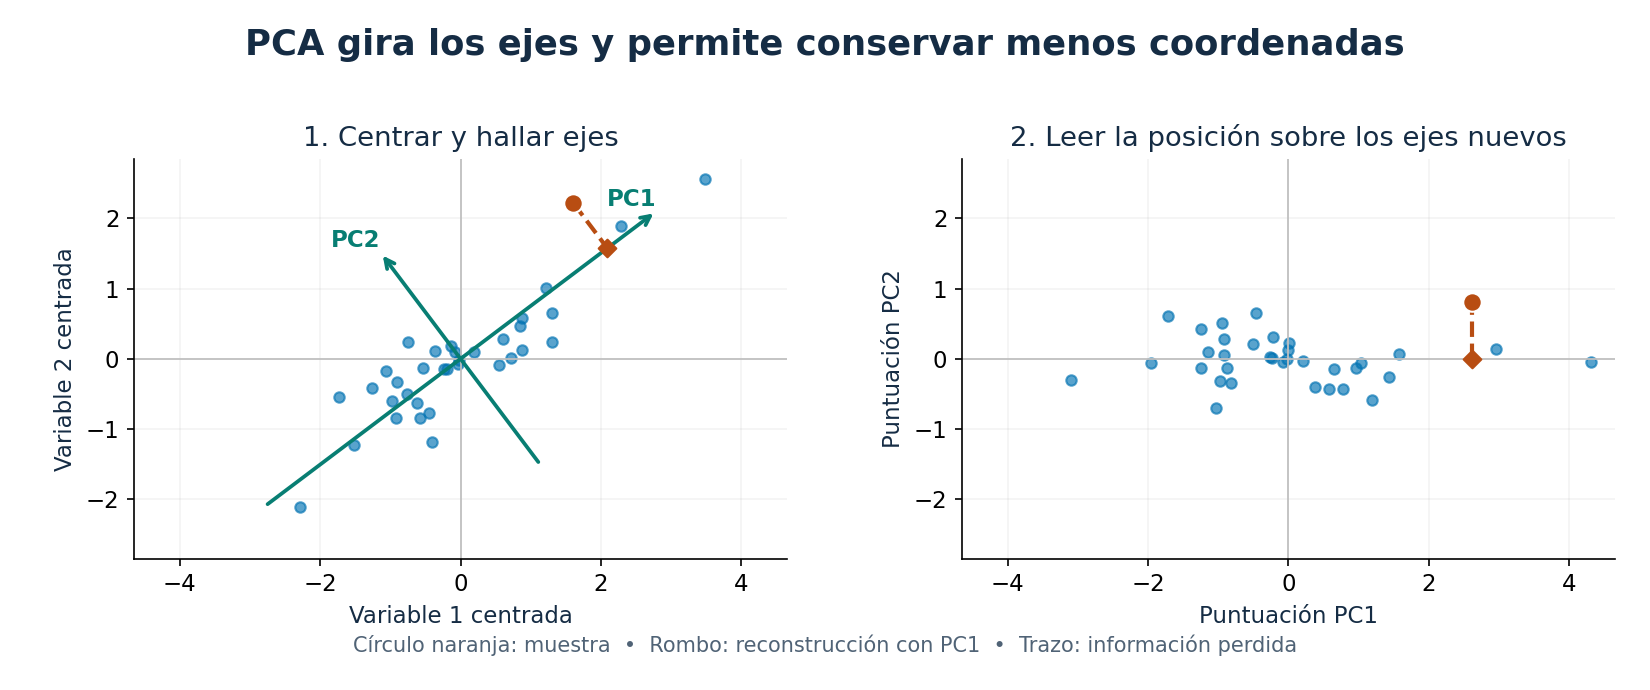

Sigue la muestra naranja. Girar los ejes cambia sus coordenadas. Descartar PC2 sí cambia la posición que podemos reconstruir.

<a id="parte-2"></a>

### <span style="color:lightgreen">**Conceptos fundamentales**</span>
***

La idea geométrica es buscar una dirección, proyectar cada fila sobre ella y guardar su coordenada. Antes de aplicar el algoritmo veremos de dónde sale esa dirección.

***

<span style="color:gold">**Varianza y covarianza**</span>

La comprensión de PCA comienza con los conceptos de varianza y covarianza.

La varianza describe cuánto se dispersan las observaciones de una variable alrededor de su media; la covarianza, por otro lado, mide cómo cambian conjuntamente dos variables. PCA se centra en encontrar las direcciones donde la varianza alcanza su máximo.

La matriz de covarianza $C$ se define como:



$$
\Large C = \frac{1}{n-1} \sum_{i=1}^n (x_i - \mu) (x_i - \mu)^T
$$


<br>
Donde $x_i$ representa cada observación, $\mu$ es el vector de medias, y $n$ es el número total de observaciones.

***

<span style="color:gold">**Autovectores y autovalores**</span>

Cada autovector da una dirección. Su autovalor mide la varianza de las proyecciones sobre esa dirección. Ordenamos las direcciones de mayor a menor autovalor.

Los autovectores forman los nuevos ejes para los datos transformados, y los autovalores indican la importancia de estos ejes:



$$
\Large Cv = \lambda v
$$


<br>
Aquí, $v$ es un autovector y $\lambda$ es el correspondiente autovalor.

<span style="color:gold">**Descomposición de valores singulares (SVD)**</span>

Podemos obtener los ejes de PCA con la SVD de la matriz de entrada **centrada**.

$$
X_c = U \Sigma V^T
$$

Las columnas de $V$ son direcciones en el espacio de las características. Los valores de la diagonal de $\Sigma$, elevados al cuadrado y divididos entre $n-1$, dan las varianzas de las puntuaciones de entrenamiento.

<span style="color:gold">**Transformación de los datos**</span>

Si decidimos estandarizar, primero calculamos $X_s$ restando la media de cada columna de entrenamiento y dividiendo por su desviación estándar. En el código PCA recibe $X_s$ y centra esa entrada con su propia media ajustada $\mu_{PCA}$. Si $V_k$ contiene los primeros $k$ ejes como columnas, entonces

$$
T_k = (X_s - \mu_{PCA}) V_k
$$

$T_k$ contiene una fila por observación y $k$ columnas. Para reconstruir, hacemos el producto $T_k V_k^T$, sumamos la media de PCA e invertimos la estandarización. Las puntuaciones de entrenamiento no están correlacionadas entre sí, aunque pueden estar relacionadas de otras maneras.

El <span style="color:gold">scree plot</span> muestra cuánta varianza aporta cada eje. Podemos guardar dos ejes para visualizar, o elegir otro número según el error de reconstrucción que resulte aceptable.

**Antes de ejecutar.** Una muestra tiene puntuación PC1 = 2 y PC2 = −1. Si solo guardas PC1, ¿dónde queda la reconstrucción en el plano de componentes?

<a id="parte-3"></a>

### <span style="color:lightgreen">**Ejemplo de PCA en geoquímica**</span>
***

Vamos a reducir nueve medidas geoquímicas de cada roca volcánica. Separaremos primero algunas filas, ajustaremos la escala y los ejes con las demás, y mediremos cuánto cuesta reconstruir medidas de las filas reservadas. El nombre de la roca se usa para colorear los puntos después del ajuste.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

Empezaremos cargando datos de rocas volcánicas almacenados en el archivo `rocas.csv`:

In [ ]:
# Cargar datos
rocas = pd.read_csv("files/rocas.csv")
rocas.sample(6, random_state=42)

Los datos del archivo contienen información geoquímica de 4 tipos de rocas volcánicas: basalto (`basalt`), andesita (`andesite`), dacita (`dacite`) y riolita (`rhyolite`).

In [ ]:
print(rocas["Nombre"].unique())

Ahora, vamos a seleccionar los datos para aplicar PCA. En este caso, eligiremos todas las columnas numéricas de elementos geoquímicos:

In [ ]:
data = rocas.drop(columns="Nombre").select_dtypes(include="number")
completas = np.isfinite(data).all(axis=1)
print(f"Filas completas: {completas.sum():,} de {len(data):,}")
data = data.loc[completas]
litologia = rocas.loc[data.index, "Nombre"]
data.sample(6, random_state=42)

In [ ]:
# Resumen estadístico de los datos
data.describe().T

Antes de ajustar podemos elegir cómo representar las concentraciones. Cambiar de escala o usar log-razones cambia la geometría que PCA ve.

- <span style="color:lightgreen">**Escalado y normalización de los datos**</span>

    Los datos geoquímicos suelen abarcar una amplia gama de magnitudes debido a la naturaleza de las concentraciones elementales.

    Por ejemplo, ciertos óxidos o elementos pueden estar presentes en porcentajes altos, mientras que los elementos traza aparecen en concentraciones mucho menores. Este desequilibrio puede hacer que las variables con mayores magnitudes dominen la varianza total, distorsionando los resultados de PCA.

    Para abordar esto, es común aplicar técnicas de escalado (normalización o estandarización):

    - **Estandarización (Z-score)**:<br>
        Consiste en restar la media y dividir por la desviación estándar de cada variable. Esto centra los datos en torno a una media de cero y una desviación estándar de uno, dando a todas las columnas no constantes la misma varianza inicial en el conjunto de ajuste.
    - **Normalización (Min-Max Scaling)**:<br>
        Transforma los datos para que todos los valores caigan en un rango específico, como [0, 1]. Aunque menos común en PCA, puede ser útil cuando se quiere mantener la relación relativa entre los valores de las variables.

- <span style="color:lightgreen">**Transformación logarítmica**</span> <br>

    Es también frecuente encontrar datos geoquímicos con distribuciones asimétricas o sesgadas hacia valores bajos, particularmente en el caso de los elementos traza.

    La **transformación logarítmica** puede ser beneficiosa para mitigar este sesgo, ya que tiende a reducir la variabilidad en los valores altos, comprimiendo las diferencias en magnitud y haciendo que la distribución de los datos sea más simétrica.

    Esto facilita que PCA capte las relaciones lineales entre las variables, que de otra forma podrían perderse debido a la alta variabilidad.

- <span style="color:lightgreen">**Transformación de datos composicionales**</span>

  Si lo que importa son las proporciones dentro de una composición, conviene considerar log-razones. CLR resta a cada logaritmo el promedio de los logaritmos de esa fila; ILR representa razones mediante coordenadas ortonormales. Esta práctica usa concentraciones estandarizadas. Esa elección no elimina la dependencia inducida por una suma fija.

  Una log-razón requiere partes positivas. Si hay ceros, primero distingue ausencia real, redondeo y concentraciones bajo el límite de detección. Un reemplazo requiere conocer ese origen y revisar su efecto en el resultado.

- <span style="color:lightgreen">**Eliminación y Sustitución de Valores Faltantes**</span> <br>
    Los datos geoquímicos de rocas volcánicas pueden contener valores faltantes debido a limitaciones en la detección de ciertos elementos traza o a variabilidad en los métodos de muestreo.

    La presencia de datos faltantes puede afectar el cálculo de PCA, ya que este requiere matrices completas. Algunos métodos comunes para manejar valores faltantes incluyen:

    - **Eliminación de muestras o variables con valores faltantes**, aunque esto puede reducir el tamaño de la muestra.
    - **Imputación de valores faltantes** mediante métodos estadísticos, como la media o mediana de la variable, o técnicas avanzadas como imputación por regresión o imputación por K-nearest neighbors (KNN).

En esta práctica separamos por filas. Si quisiéramos evaluar una campaña o un sondaje nuevos, reservaríamos ese grupo completo. Ajustamos `StandardScaler` antes de proyectar ninguna fila de prueba.

In [ ]:
ajuste, prueba = train_test_split(data, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(ajuste)
data_scaled = scaler.transform(ajuste)
prueba_scaled = scaler.transform(prueba)
print(f"Ajuste: {ajuste.shape}   Prueba: {prueba.shape}")

In [ ]:
primera = (ajuste.iloc[0].to_numpy() - scaler.mean_) / scaler.scale_
tabla = pd.DataFrame({"Original": ajuste.iloc[0], "Media de ajuste": scaler.mean_,
                      "Escalada a mano": primera, "transform": data_scaled[0]})
tabla.round(3)

Primero conservamos todos los componentes. Así podemos comparar distintas cantidades de ejes a partir del mismo ajuste.

In [ ]:
pca = PCA(svd_solver="full").fit(data_scaled)
data_pca = pca.transform(data_scaled)
prueba_pca = pca.transform(prueba_scaled)
explained_variance = pca.explained_variance_ratio_

A mano, la primera PC es un producto entre la fila centrada y la primera fila de `components_`. Decide qué forma tendrá el resultado antes de ejecutar.

In [ ]:
pc1_manual = (primera - pca.mean_) @ pca.components_[0]
print(f"PC1 a mano: {pc1_manual:.4f}   PC1 de transform: {data_pca[0, 0]:.4f}")
print(f"Forma de components_: {pca.components_.shape}")

Una fila de `components_` describe una dirección. Una fila de `prueba_pca` describe la posición de una roca en esas direcciones.

In [ ]:
nombres_pc = [f"PC{i+1}" for i in range(pca.n_components_)]
puntuaciones = pd.DataFrame(prueba_pca, columns=nombres_pc, index=prueba.index)
puntuaciones.head().round(3)

Las barras muestran la proporción de varianza del ajuste en cada componente. Elegiremos el menor número de componentes que acumula al menos 85% en ajuste. Es un criterio didáctico que fijamos antes de mirar la prueba.

In [ ]:
indices_pc = np.arange(1, pca.n_components_ + 1)
acumulada = explained_variance.cumsum()
k = int(np.searchsorted(acumulada, 0.85) + 1)
fig, ax = plt.subplots(figsize=(8.4, 4.2))
ax.bar(indices_pc, explained_variance, color="#0072B2", label="Por componente")
ax.plot(indices_pc, acumulada, "o-", color="#B84D12", label="Acumulada")
ax.axhline(0.85, color="0.4", ls="--", label="Criterio de 85%")
ax.axvline(k, color="#087E73", ls=":", label=f"k = {k}")
ax.set(xticks=indices_pc, xlabel="Componente", ylabel="Proporción de varianza de ajuste", ylim=(0, 1.06))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**¿Qué perdemos al reducir?** Ponemos a cero las puntuaciones de los ejes que no guardamos y reconstruimos con `inverse_transform`. La prueba mide el error en filas que quedaron fuera de ambos ajustes. El RMSE en unidades estandarizadas permite resumir columnas de escalas distintas.

In [ ]:
# Guardar solo k puntuaciones de cada roca de prueba.
comprimido = prueba_pca.copy()
comprimido[:, k:] = 0.0
reconstruccion_scaled = pca.inverse_transform(comprimido)
reconstruccion = scaler.inverse_transform(reconstruccion_scaled)
rmse_k = np.sqrt(np.mean((prueba_scaled - reconstruccion_scaled) ** 2))
rmse_completo = np.sqrt(np.mean((prueba_scaled - pca.inverse_transform(prueba_pca)) ** 2))
print(f"RMSE con {k} componentes: {rmse_k:.3f}")
print(f"RMSE con todos: {rmse_completo:.3e}")
pd.DataFrame({"Observado": prueba.iloc[0], "Reconstruido": reconstruccion[0]}).round(2)

Leemos cada dirección en `components_`. Para interpretar relaciones en un gráfico calculamos, por separado, la correlación de cada medida con las puntuaciones de ajuste.

In [ ]:
components = pd.DataFrame(pca.components_.T, columns=nombres_pc, index=data.columns)
correlaciones = pd.DataFrame(
    np.corrcoef(data_scaled.T, data_pca.T)[:data.shape[1], data.shape[1]:],
    index=data.columns, columns=nombres_pc,
)
components.iloc[:, :3].round(3)

Un coeficiente indica cuánto pesa una medida estandarizada en la coordenada. Podemos invertir el signo de un eje entero junto con sus puntuaciones sin cambiar la reconstrucción. El panel de correlaciones muestra valores entre −1 y 1 en su propia escala.

Empezaremos viendo dos componentes. Los colores de las rocas sirven para comparar patrones después del ajuste, aunque PCA nunca recibió la columna `Nombre`.

In [ ]:
muestra = puntuaciones.sample(min(1600, len(puntuaciones)), random_state=42)
etiquetas = litologia.loc[muestra.index]
colores = {"basalt": "#0072B2", "andesite": "#B84D12", "dacite": "#087E73", "rhyolite": "#884C9B"}

fig, (ax, corr) = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={"width_ratios": [1.7, 1]})
for roca, grupo in muestra.groupby(etiquetas):
    ax.scatter(grupo["PC1"], grupo["PC2"], s=13, alpha=.6, color=colores[roca], label=roca)
ax.set(title="Rocas de prueba en dos componentes",
       xlabel=f"PC1 ({explained_variance[0]:.1%})", ylabel=f"PC2 ({explained_variance[1]:.1%})")
ax.legend(frameon=False)
ax.grid(alpha=.19)

valores = correlaciones.iloc[:, :3].to_numpy()
im = corr.imshow(valores, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
corr.set(xticks=[0, 1, 2], xticklabels=nombres_pc[:3],
         yticks=range(len(data.columns)), yticklabels=data.columns,
         title="Correlación con las puntuaciones de ajuste")
for fila, columna in np.ndindex(valores.shape):
    r = valores[fila, columna]
    corr.text(columna, fila, f"{r:+.2f}", ha="center", va="center",
              color="white" if abs(r) > .64 else "black", fontsize=9)
fig.colorbar(im, ax=corr, label="r", shrink=.78)
fig.tight_layout()
plt.show()

Puedes girar el gráfico para ver si PC3 distingue rocas que se superponen en PC1 y PC2. Mostramos el mismo subconjunto de prueba y las correlaciones quedan en el panel separado.

In [ ]:
import sys
import plotly.graph_objects as go
import plotly.io as pio

if sys.platform == "emscripten":
    pio.renderers.default = "plotly_mimetype"
fig3d = go.Figure()
for roca, grupo in muestra.groupby(etiquetas):
    fig3d.add_scatter3d(x=grupo["PC1"], y=grupo["PC2"], z=grupo["PC3"], mode="markers",
                        name=roca, marker=dict(size=3, opacity=.62, color=colores[roca]))
fig3d.update_layout(title="Puntuaciones de las rocas de prueba",
                    scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3",
                               aspectmode="data"), height=475,
                    margin=dict(l=0, r=0, b=0, t=50))
fig3d.show()

<a id="parte-4"></a>

### <span style="color:lightgreen">**En conclusión...**</span>
***

`fit` aprendió una media y nuevos ejes, `transform` ubicó cada muestra y la reconstrucción hizo visible el costo de descartar componentes. Antes de interpretar qué separa a las rocas, revisa cómo se midieron las concentraciones y qué representa la variación observada.

**Comprueba tu lectura.** Cambia el número de componentes en la reconstrucción, explica por qué cambia el RMSE y señala qué parte del código conserva la columna `Nombre` fuera del ajuste. ¿Qué esperarías si aplicas los ejes a otra campaña?

En [Clustering con K-means y DBSCAN](pg202b_clustering.ipynb) cambiaremos de pregunta. En vez de comprimir variables, buscaremos grupos de muestras.

[Referencia de PCA en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)

***